# GenVerOpt reproduction — Stage 3d: diagnose the question image, clean the crops
Stage 3c result: 2,199 of 2,710 items parsed (81%); 1,449 prompts mention a question mark; **1,415 are both** (usable subset). For reference, the paper's Tab. 1 sums to 1,263 puzzles, so this is the same order of magnitude.

Two problems seen in the 3c figure:
1. The **question column was blank in all six samples**. Cause unknown, so the question image is untrusted until diagnosed here.
2. **Crops carry frame fragments** (thick border rules, slivers of the neighbouring option).

Generated; the new functions were checked on one synthetic image only, not on the real data.

In [1]:
!pip -q install datasets pillow matplotlib scipy
import random, re, numpy as np
from collections import Counter
from PIL import Image
from datasets import load_dataset
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)
ds = load_dataset("afdsafas/MMIQ")["train"]

data/train_1.parquet: reconstructing file:   0%|          |  0.00B /  116MB            

data/train_1.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2710 [00:00<?, ? examples/s]

## 1. Helpers (copied unchanged from 3c)

In [2]:
MAX_SIDE = 1600

def to_rgb_white(im):
    """Composite transparency on white (naive convert() turns transparent pixels black), then cap size."""
    if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        bg.alpha_composite(im)
        im = bg.convert("RGB")
    else:
        im = im.convert("RGB")
    s = max(im.size)
    if s > MAX_SIDE:
        f = MAX_SIDE / s
        im = im.resize((max(1, round(im.width * f)), max(1, round(im.height * f))), Image.LANCZOS)
    return im

def runs(mask, min_gap):
    idx = np.flatnonzero(mask)
    if idx.size == 0: return []
    out, s, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev > min_gap:
            out.append((int(s), int(prev) + 1)); s = i
        prev = i
    out.append((int(s), int(prev) + 1))
    return out

def thin_rules(ink):
    """Boolean per row: True for thin, nearly full-width horizontal lines (frame borders)."""
    h, w = ink.shape
    dense = ink.mean(1) > 0.6
    rule = np.zeros(h, bool)
    for a, b in runs(dense, 0):
        if b - a <= max(3, int(0.012 * h)): rule[a:b] = True
    return rule

def extract(im):
    """Return dict(ok, reason, crops(4), question(masked), info). Option positions come from the A-D label glyphs."""
    im = to_rgb_white(im)
    g = np.asarray(im.convert("L")); ink = g < 200
    h, w = ink.shape
    rule = thin_rules(ink)
    bands = runs(ink.any(1) & ~rule, 1)
    if len(bands) < 2: return dict(ok=False, reason="few_bands", img=im)
    l0, l1 = bands[-1]
    cols = runs(ink[l0:l1].any(0), max(3, int(0.01 * w)))
    if len(cols) != 4: return dict(ok=False, reason=f"clusters={len(cols)}", img=im)
    if (l1 - l0) > 0.25 * h: return dict(ok=False, reason="label_band_too_tall", img=im)
    cx = np.array([(a + b) / 2 for a, b in cols])
    cw = np.mean([b - a for a, b in cols])
    if cw > 0.2 * w: return dict(ok=False, reason="clusters_too_wide", img=im)
    d = np.diff(cx)
    if d.std() / d.mean() > 0.35: return dict(ok=False, reason="uneven_spacing", img=im)
    xe = np.concatenate([[max(0, cx[0] - d[0] / 2)], (cx[:-1] + cx[1:]) / 2, [min(w, cx[-1] + d[-1] / 2)]]).astype(int)
    o0, o1 = bands[-2]
    # extend vertically to include any rule rows touching the option band, then crop
    crops = [im.crop((int(xe[i]), o0, int(xe[i + 1]), o1)) for i in range(4)]
    q = np.asarray(im).copy()
    q[o0:h, xe[0]:xe[-1]] = 255
    return dict(ok=True, reason="ok", img=im, crops=crops, question=Image.fromarray(q),
                info=dict(label_band=(l0, l1), option_band=(o0, o1), xe=xe.tolist()))

## 2. Diagnose the blank question image

In [3]:
def ink_frac(img):
    return float((np.asarray(img.convert("L")) < 200).mean())

def diagnose(i):
    r = extract(ds[i]["image"])
    if not r["ok"]:
        print(f"#{i}: not parsed ({r['reason']})"); return r
    h, w = r["img"].height, r["img"].width
    print(f"#{i}: size={w}x{h}  label_band={r['info']['label_band']}  option_band={r['info']['option_band']}  xe={r['info']['xe']}")
    print(f"     ink fraction: original={ink_frac(r['img']):.4f}  question={ink_frac(r['question']):.4f}  crops={[round(ink_frac(c),4) for c in r['crops']]}")
    return r

sample_ids = [1469, 1563, 124, 1108, 1846, 1781]      # the six items from the 3c figure
diag = {i: diagnose(i) for i in sample_ids}

# dataset-wide: how often is the question image (nearly) empty?
q_ink = []
for i in range(len(ds)):
    r = extract(ds[i]["image"])
    if r["ok"]: q_ink.append((i, ink_frac(r["question"])))
q = np.array([v for _, v in q_ink])
print("parsed items:", len(q), "| question ink < 0.2%:", int((q < 0.002).sum()), "| median question ink:", round(float(np.median(q)), 4))

#1469: size=816x339  label_band=(307, 327)  option_band=(159, 283)  xe=[168, 283, 397, 519, 650]
     ink fraction: original=0.1136  question=0.0653  crops=[0.1858, 0.2076, 0.2464, 0.2107]
#1563: size=1377x564  label_band=(525, 554)  option_band=(289, 498)  xe=[266, 474, 683, 894, 1104]
     ink fraction: original=0.1210  question=0.0824  crops=[0.132, 0.1102, 0.1293, 0.134]
#124: size=447x194  label_band=(176, 190)  option_band=(91, 161)  xe=[82, 153, 224, 295, 366]
     ink fraction: original=0.1013  question=0.0684  crops=[0.1046, 0.0998, 0.0956, 0.1028]
#1108: size=668x277  label_band=(256, 274)  option_band=(138, 241)  xe=[118, 225, 333, 444, 558]
     ink fraction: original=0.1715  question=0.1140  crops=[0.1765, 0.152, 0.1998, 0.2134]
#1846: size=454x164  label_band=(151, 162)  option_band=(78, 145)  xe=[101, 166, 230, 295, 360]
     ink fraction: original=0.1050  question=0.0565  crops=[0.2044, 0.1919, 0.1589, 0.2218]
#1781: size=484x191  label_band=(179, 191)  option_band=(97,

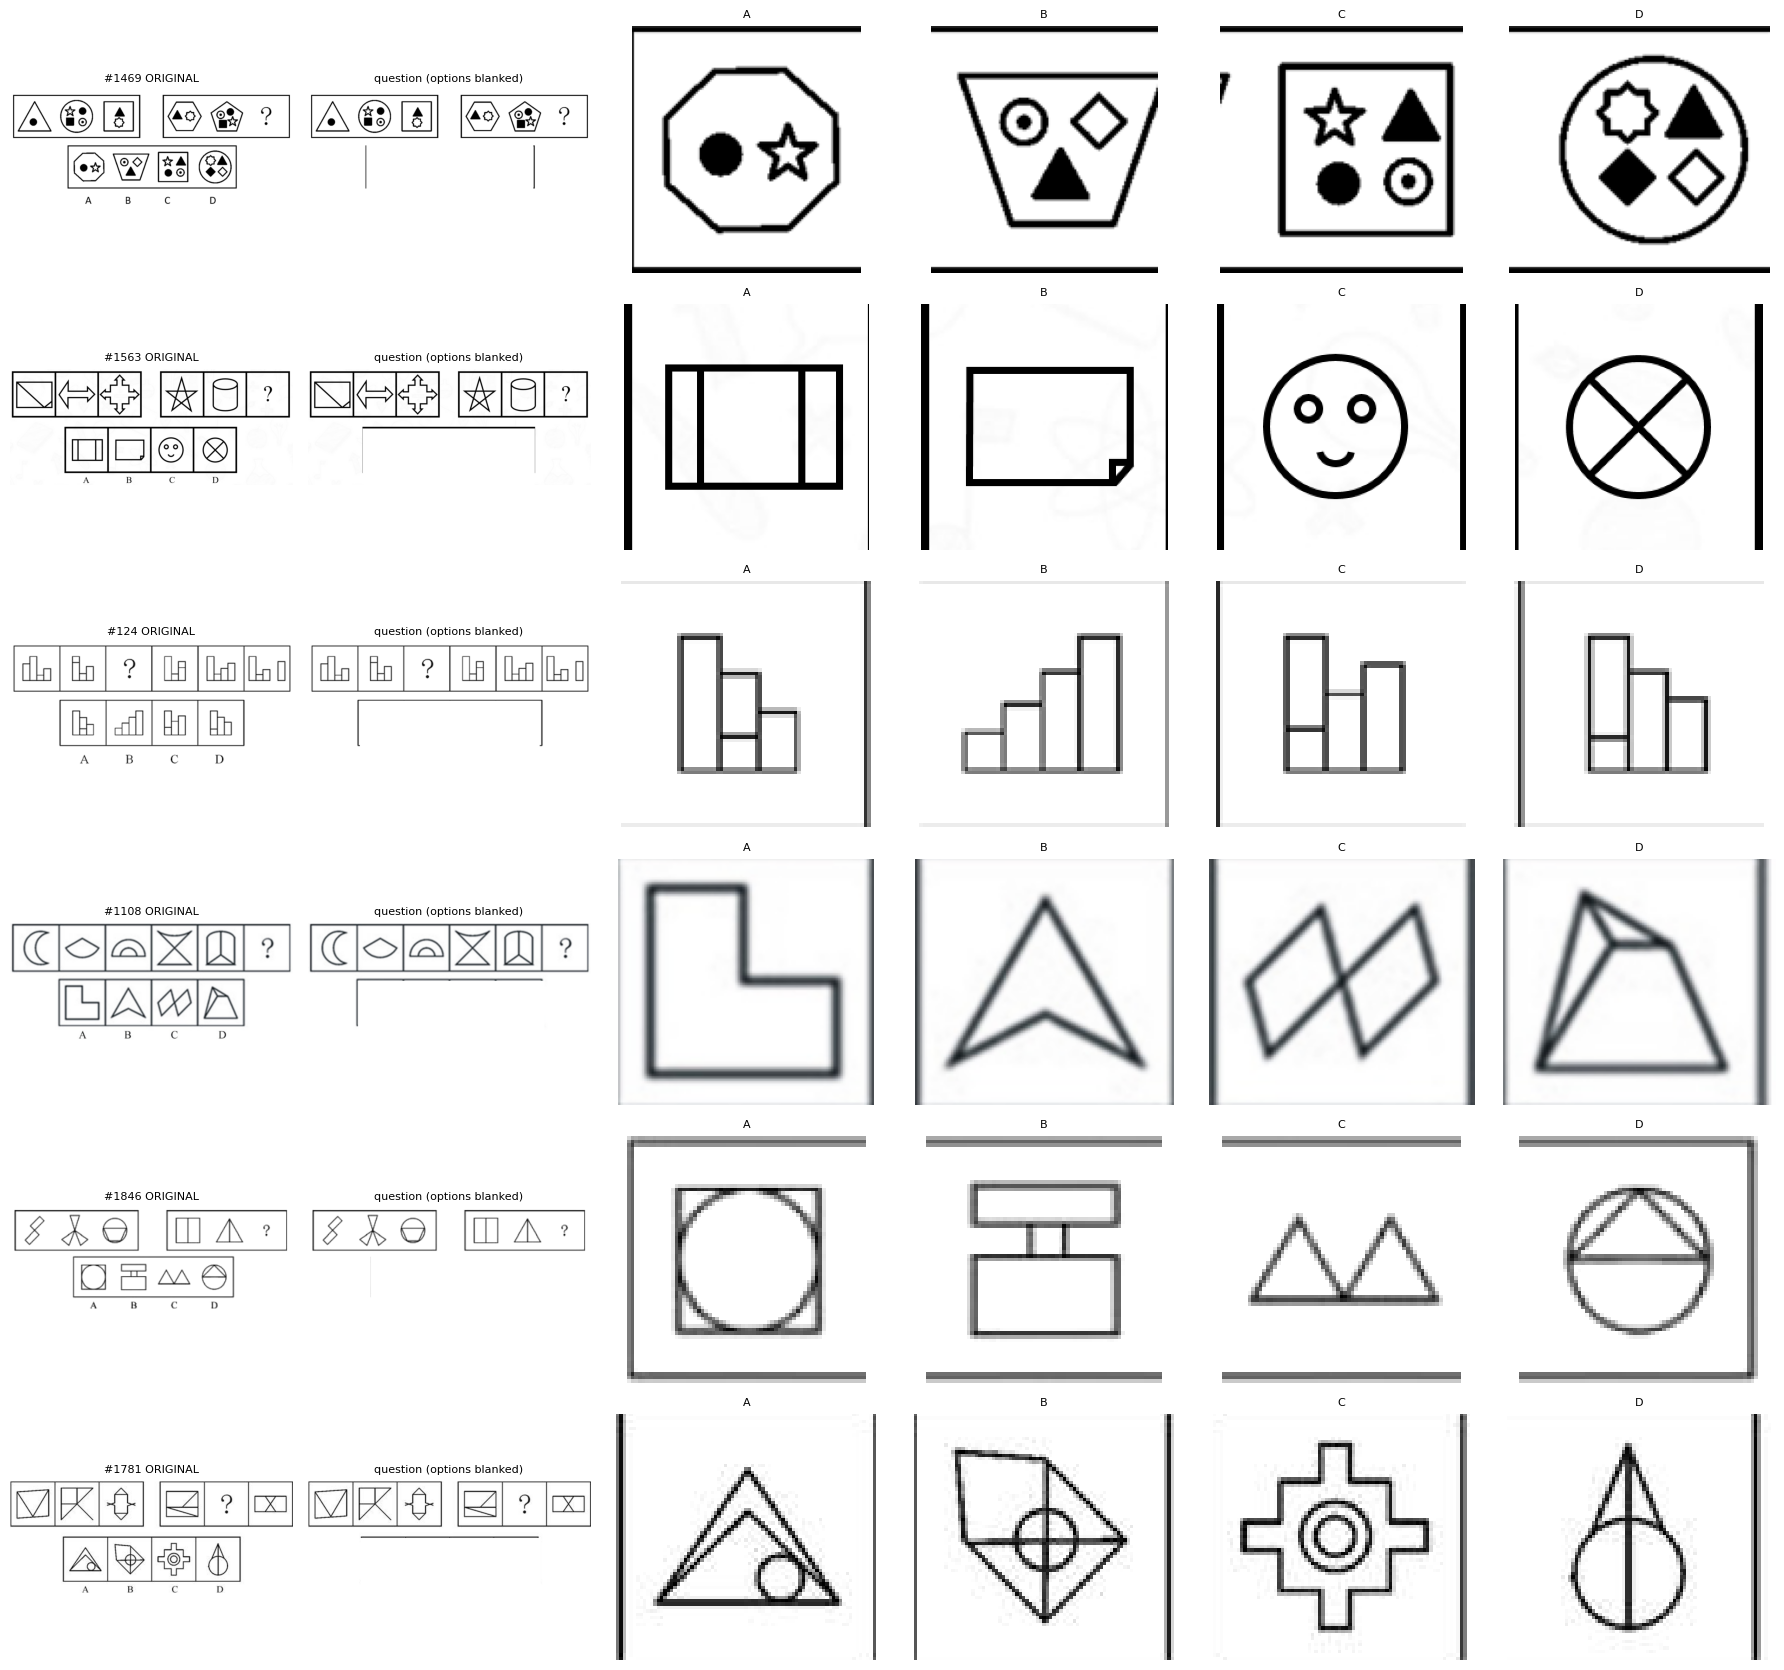

In [4]:
fig, axes = plt.subplots(len(sample_ids), 6, figsize=(18, 2.8 * len(sample_ids)), squeeze=False)
for row, i in enumerate(sample_ids):
    r = diag[i]
    if not r["ok"]: continue
    axes[row][0].imshow(r["img"]); axes[row][0].set_title(f"#{i} ORIGINAL", fontsize=8)
    axes[row][1].imshow(r["question"]); axes[row][1].set_title("question (options blanked)", fontsize=8)
    for k in range(4):
        axes[row][k + 2].imshow(r["crops"][k]); axes[row][k + 2].set_title("ABCD"[k], fontsize=8)
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig("/content/diag_question.png", dpi=100); plt.show()

## 3. Crop cleaning (experimental)
Removes thin full-length border lines near the crop edges, tight-crops to the remaining ink, and pads to a white square. It does **not** remove small slivers of a neighbouring option.

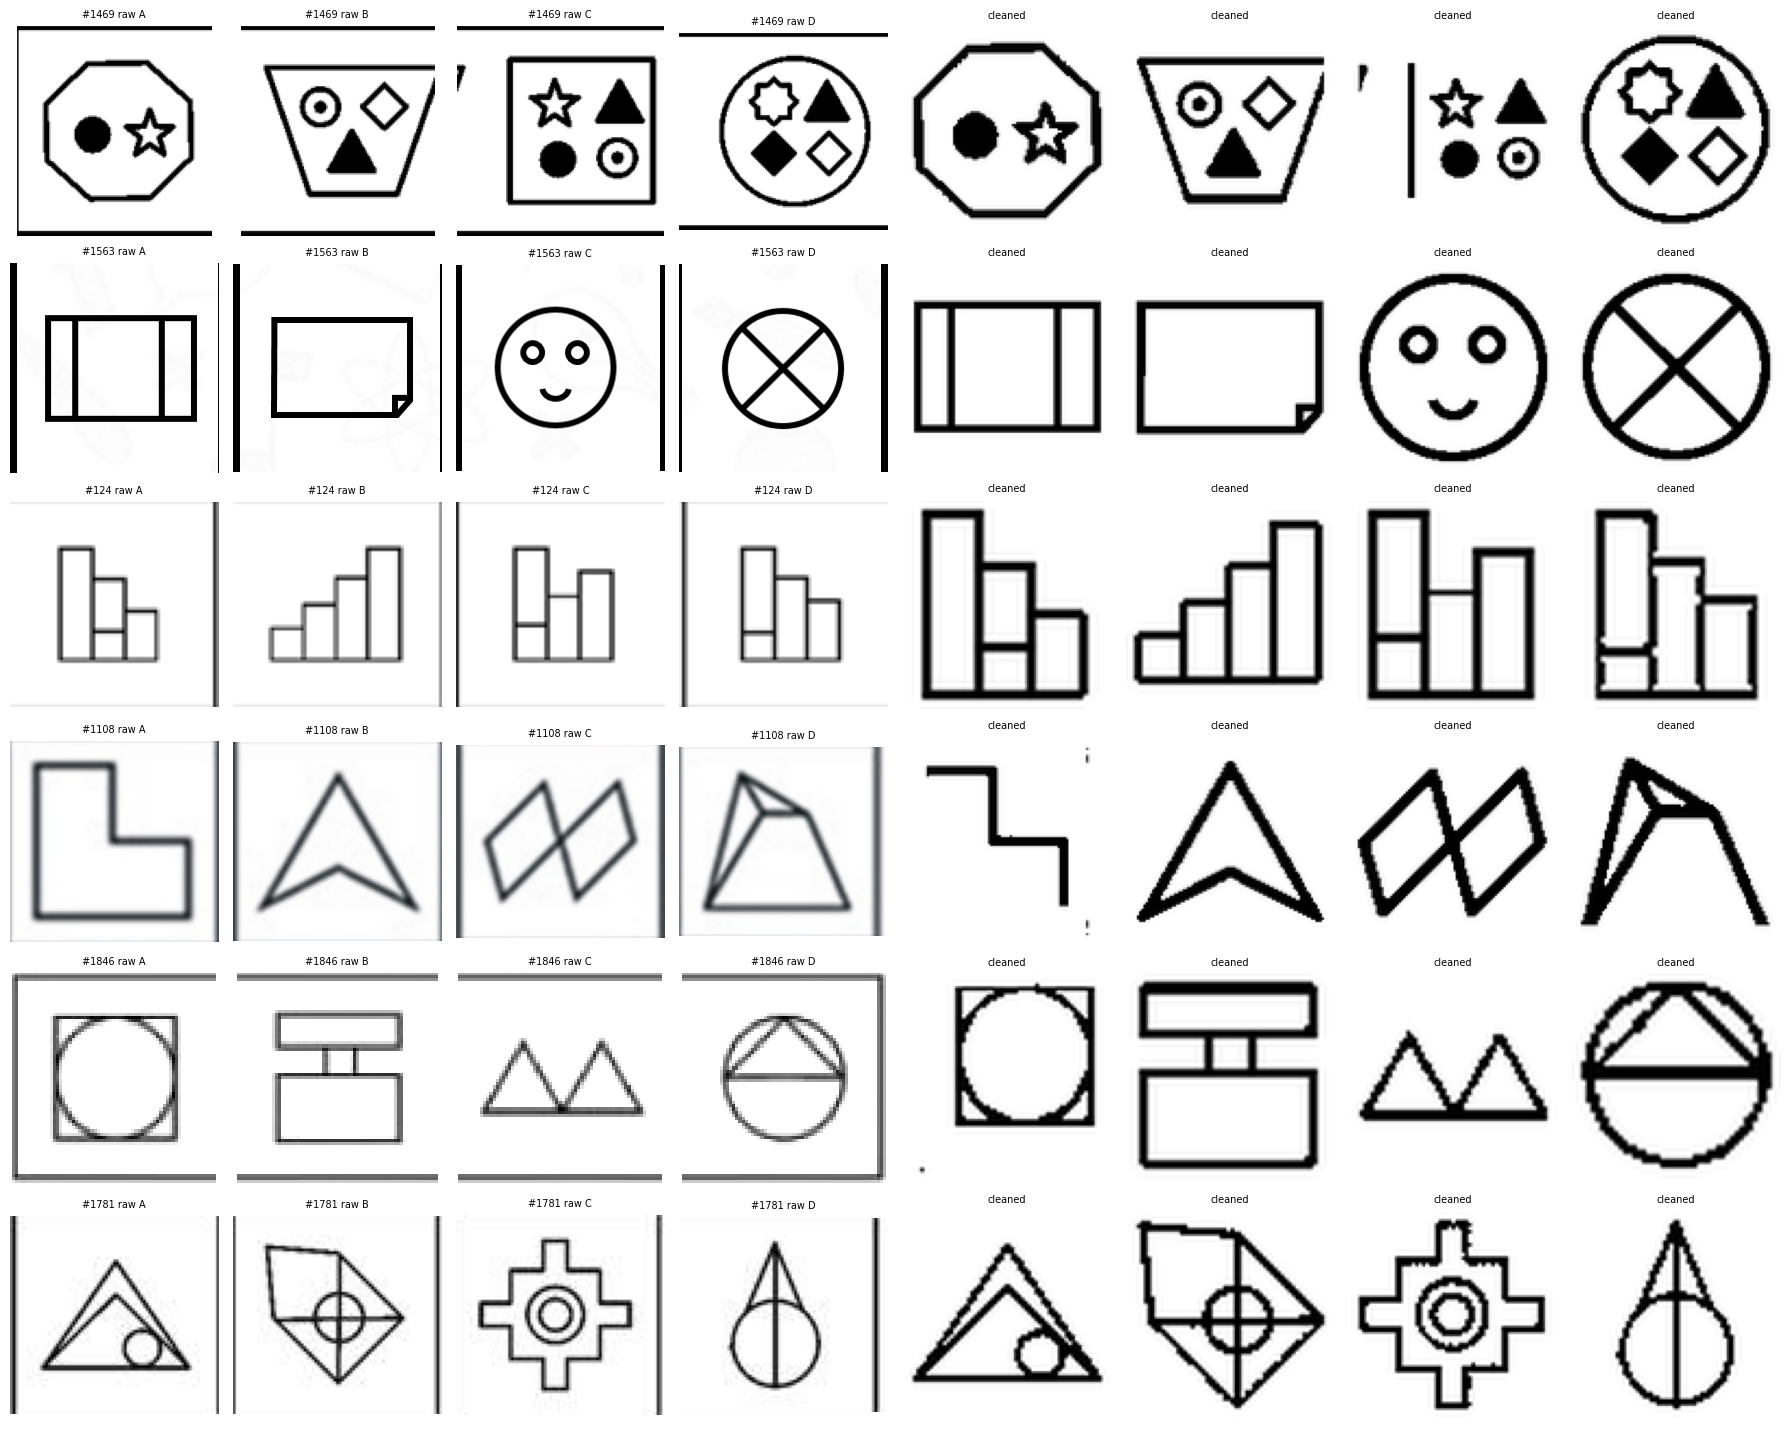

In [5]:
def clean_crop(c, size=96, edge=0.18, line_frac=0.7, margin=0.06):
    a = np.asarray(c.convert("L")) < 200
    h, w = a.shape
    if a.sum() == 0: return Image.new("RGB", (size, size), "white")
    # drop border rows/cols near the edges that are mostly ink (frame rules)
    rows = a.mean(1) > line_frac; cols = a.mean(0) > line_frac
    keep_r = np.ones(h, bool); keep_c = np.ones(w, bool)
    er, ec = int(edge * h), int(edge * w)
    keep_r[:er] &= ~rows[:er]; keep_r[h - er:] &= ~rows[h - er:]
    keep_c[:ec] &= ~cols[:ec]; keep_c[w - ec:] &= ~cols[w - ec:]
    a = a & keep_r[:, None] & keep_c[None, :]
    ys, xs = np.where(a)
    if ys.size == 0: return Image.new("RGB", (size, size), "white")
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    out = np.where(a[y0:y1, x0:x1], 0, 255).astype(np.uint8)
    s = int(max(out.shape) * (1 + 2 * margin))
    canvas = np.full((s, s), 255, np.uint8)
    oy, ox = (s - out.shape[0]) // 2, (s - out.shape[1]) // 2
    canvas[oy:oy + out.shape[0], ox:ox + out.shape[1]] = out
    return Image.fromarray(canvas).convert("RGB").resize((size, size), Image.LANCZOS)

fig, axes = plt.subplots(len(sample_ids), 8, figsize=(18, 2.4 * len(sample_ids)), squeeze=False)
for row, i in enumerate(sample_ids):
    r = diag[i]
    if not r["ok"]: continue
    for k in range(4):
        axes[row][k].imshow(r["crops"][k]); axes[row][k].set_title(f"#{i} raw {'ABCD'[k]}", fontsize=7)
        axes[row][k + 4].imshow(clean_crop(r["crops"][k])); axes[row][k + 4].set_title("cleaned", fontsize=7)
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig("/content/diag_clean.png", dpi=100); plt.show()

Send back: the printed lines from section 2 (per-item diagnostics and the dataset-wide question-ink summary) and the two saved figures `diag_question.png` and `diag_clean.png`.